# 05 · Evaluación final y validación en escenarios simulados

Este notebook usa la **prueba (200 quejas) una sola vez**. Sigue las secciones de la Semana 5: métricas básicas, evaluación estadística, métricas del dominio, sesgo por subgrupo, abstención y cobertura, pruebas de estrés y desempeño en el tiempo.

**Criterios fijados antes de ver la prueba** (en `config.yaml`):

| Criterio | Valor | Origen |
|---|---|---|
| Caída máxima de F1-macro en una prueba de estrés | 0,05 | Margen entre el umbral mínimo (0,65) y el objetivo (0,70) de F1 de la tarea B en el Documento de Alcance |
| Brecha máxima de F1 entre subgrupos con n ≥ 30 | 0,10 | Compromiso ético de la Semana 4 |
| Recall mínimo de prioridad alta | 0,90 | Compromiso ético de la Semana 4 (R5) |
| Subgrupo con n < 30 | se reporta sin concluir | Retroalimentación de la Semana 4 |
| Abstención máxima | 15 % | KPI del Documento de Alcance |

In [1]:
# Preparación del entorno. En Colab, el repositorio vive en Google Drive para que los 5 notebooks compartan
# datos, modelos y resultados entre sesiones.
import os, sys, json, time, platform, shutil
EN_COLAB = "google.colab" in sys.modules
REPO = "github.com/jobedon/triajeia-isp.git"   # repositorio privado
if EN_COLAB:
    from google.colab import drive, userdata
    drive.mount("/content/drive")
    DESTINO = "/content/drive/MyDrive/triajeia-isp"
    ZIP = "/content/drive/MyDrive/triajeia-isp.zip"
    try:
        TOKEN = userdata.get("GITHUB_TOKEN")      # Secretos de Colab (🔑): token de solo lectura
    except Exception:
        TOKEN = None
    if TOKEN:
        url = f"https://x-access-token:{TOKEN}@{REPO}"
        if not os.path.exists(f"{DESTINO}/.git"):
            r = os.system(f"git clone -q {url} {DESTINO} > /dev/null 2>&1")
        else:
            r = os.system(f"git -C {DESTINO} pull -q {url} main > /dev/null 2>&1")
        print("Código actualizado desde GitHub" if r == 0 else "No se pudo usar GitHub; se usa la copia de Drive")
    elif not os.path.exists(DESTINO) and os.path.exists(ZIP):
        shutil.unpack_archive(ZIP, "/content/drive/MyDrive")
        print("Código extraído de triajeia-isp.zip")
    if not os.path.exists(f"{DESTINO}/config.yaml"):
        raise FileNotFoundError("No se encontró el código. Agregue el secreto GITHUB_TOKEN o suba triajeia-isp.zip a la raíz de Drive.")
    os.chdir(DESTINO)
    os.system('pip install -q "scikit-learn==1.6.1" "optuna>=4" "fairlearn>=0.12"')
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
PRUEBA_RAPIDA = os.environ.get("PRUEBA_RAPIDA", "0") == "1"   # solo para verificar el código; sus números no se usan
print("Directorio:", os.getcwd(), "| Colab:", EN_COLAB, "| Prueba rápida:", PRUEBA_RAPIDA)

Mounted at /content/drive
Código actualizado desde GitHub
Directorio: /content/drive/MyDrive/triajeia-isp | Colab: True | Prueba rápida: False


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from src.utils import cargar_config, cargar_json, fijar_semilla, guardar_json

cfg = cargar_config()
SEMILLA = cfg["semilla"]
fijar_semilla(SEMILLA)
FIG, MET = "results/figures", "results/metrics"
os.makedirs(FIG, exist_ok=True); os.makedirs(MET, exist_ok=True); os.makedirs("models", exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
GRANATE = "#791632"

def guardar_fig(nombre):
    plt.tight_layout()
    plt.savefig(f"{FIG}/{nombre}.png", dpi=150, bbox_inches="tight")
    plt.show()

def entorno():
    e = {"colab": EN_COLAB, "prueba_rapida": PRUEBA_RAPIDA, "python": platform.python_version(),
         "sklearn": sklearn.__version__, "pandas": pd.__version__, "fecha": time.strftime("%Y-%m-%d %H:%M")}
    try:
        import torch
        e["torch"] = torch.__version__
        e["gpu"] = torch.cuda.get_device_name(0) if torch.cuda.is_available() else None
    except ImportError:
        e["gpu"] = None
    return e
NB = "05"

In [3]:
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from src.evaluate import (abstencion_por_subgrupo, con_erratas, costo_esperado, ic_bootstrap, ic_diferencia, mcnemar,
                          metricas, por_subgrupo, quitar_palabras, quitar_terminos, recall_clase, riesgo_cobertura, truncar)
from src.model import ClasificadorTriaje, construir_svm
E = cfg["evaluacion"]; P = cfg["datos"]["procesados"]; OBJ = cfg["datos"]["objetivos"]
NB_BOOT = 200 if PRUEBA_RAPIDA else E["bootstrap"]
dev = pd.concat([pd.read_csv(f"{P}/train.csv"), pd.read_csv(f"{P}/val.csv")], ignore_index=True)
test = pd.read_csv(f"{P}/test.csv")
modelo = ClasificadorTriaje.cargar("models/best_model.joblib")
print(modelo.metadatos)

{'version': 'v2_svm_final', 'params': {'categoria': {'C': 0.3, 'palabra_ngramas': [1, 2], 'caracter_ngramas': [3, 5], 'min_df': 1, 'sublinear_tf': True, 'class_weight': 'balanced', 'usar_caracteres': True, 'calibracion_cv': 5}, 'prioridad': {'C': 7.924996645011359, 'palabra_ngramas': [1, 3], 'caracter_ngramas': [2, 6], 'min_df': 1, 'sublinear_tf': False, 'class_weight': 'balanced', 'usar_caracteres': True, 'calibracion_cv': 5}}, 'entrenado_con': 'train+val (1.300)', 'sklearn': '1.6.1'}


## 1. Umbral de abstención (fijado sin mirar la prueba)

Con predicciones *out-of-fold* sobre los 1.300 textos de desarrollo se elige el umbral de confianza más alto que mantiene la abstención en ≤ 15 %.

In [4]:
conf_oof = {}
for o in OBJ:
    pr = cross_val_predict(construir_svm(modelo.metadatos["params"][o], SEMILLA), dev["texto"], dev[o],
                           cv=StratifiedKFold(5, shuffle=True, random_state=SEMILLA), method="predict_proba", n_jobs=-1)
    conf_oof[o] = pr.max(1)
conf_min = np.minimum(conf_oof["categoria"], conf_oof["prioridad"])
candidatos = [u for u in np.round(np.arange(0.20, 0.95, 0.01), 2) if np.mean(conf_min < u) <= 0.15]
UMBRAL = float(max(candidatos)) if candidatos else 0.2
modelo.umbral = UMBRAL
print(f"Umbral elegido: {UMBRAL:.2f} · abstención en desarrollo: {np.mean(conf_min < UMBRAL):.1%}")
modelo.guardar("models/best_model.joblib")

Umbral elegido: 0.59 · abstención en desarrollo: 14.9%


20:18:06 | INFO | src.model | Modelo guardado en /content/drive/MyDrive/triajeia-isp/models/best_model.joblib
INFO:src.model:Modelo guardado en /content/drive/MyDrive/triajeia-isp/models/best_model.joblib


PosixPath('/content/drive/MyDrive/triajeia-isp/models/best_model.joblib')

## 2. Métricas básicas en la prueba

In [5]:
pred = {o: modelo.modelos[o].predict(test["texto"]) for o in OBJ}
proba = {o: modelo.modelos[o].predict_proba(test["texto"]) for o in OBJ}
conf = {o: proba[o].max(1) for o in OBJ}
res = {}
for o in OBJ:
    m = metricas(test[o], pred[o]); m["ic_f1"] = ic_bootstrap(test[o], pred[o], n=NB_BOOT)
    from sklearn.dummy import DummyClassifier
    dmy = DummyClassifier(strategy="most_frequent").fit(dev["texto"], dev[o]).predict(test["texto"])
    m["dummy_f1"] = metricas(test[o], dmy)["f1_macro"]
    res[o] = m
    print(f"{o}: F1-macro {m['f1_macro']:.3f} IC95 [{m['ic_f1'][1]:.3f}; {m['ic_f1'][2]:.3f}] · exactitud {m['exactitud']:.3f} · "
          f"dummy {m['dummy_f1']:.3f}")
pd.DataFrame(res["categoria"]["por_clase"]).T.round(3)

categoria: F1-macro 0.985 IC95 [0.961; 1.000] · exactitud 0.985 · dummy 0.029
prioridad: F1-macro 0.875 IC95 [0.824; 0.922] · exactitud 0.875 · dummy 0.197


,precision,recall,f1,n
AGENDAMIENTO_VISITA,1.000,1.000,1.000,16.0
ATENCION_CLIENTE,1.000,1.000,1.000,14.0
CANCELACION_TRASLADO_PLAN,1.000,0.900,0.947,10.0
DANO_FISICO_RED,1.000,1.000,1.000,12.0
FACTURACION,0.957,1.000,0.978,22.0
INSTALACION,1.000,1.000,1.000,14.0
INTERMITENCIA,1.000,0.929,0.963,28.0
SIN_SERVICIO,1.000,1.000,1.000,34.0
VELOCIDAD_LENTA,0.963,1.000,0.981,26.0
WIFI_EQUIPO,0.960,1.000,0.980,24.0


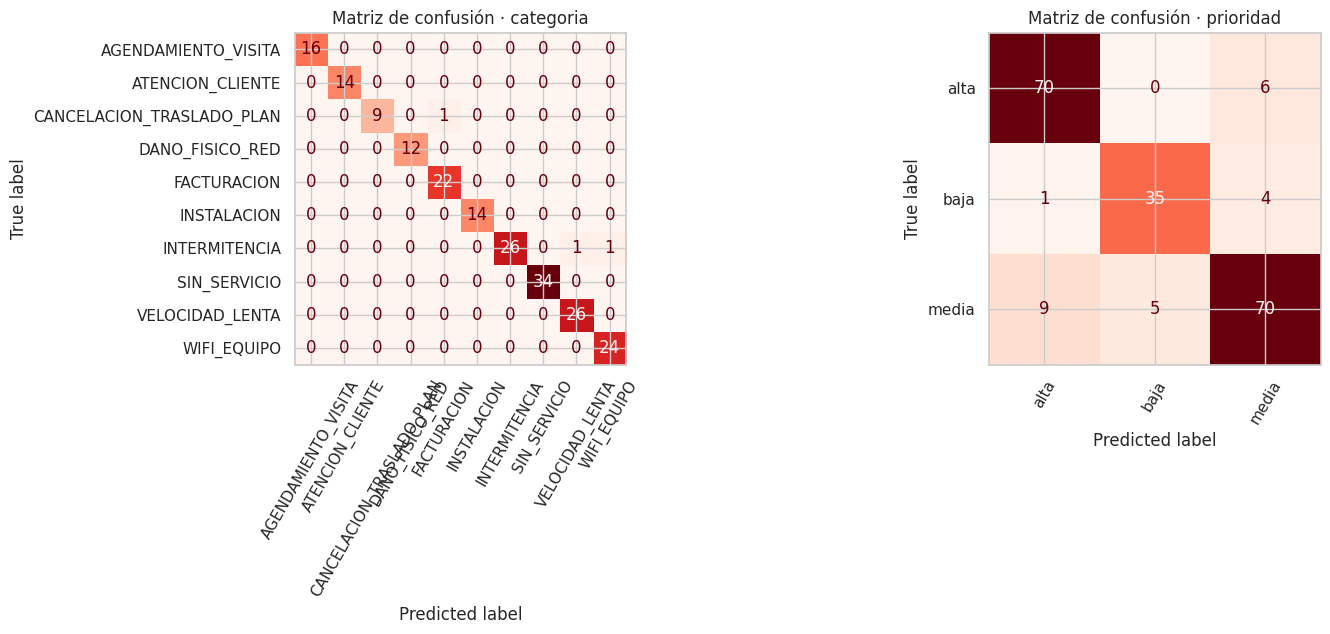

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [2, 1]})
for a, o in zip(ax, OBJ):
    ConfusionMatrixDisplay.from_predictions(test[o], pred[o], ax=a, cmap="Reds", colorbar=False, xticks_rotation=60)
    a.set_title(f"Matriz de confusión · {o}")
guardar_fig("05_matrices_confusion")

## 3. Comparación estadística con XLM-R (de `03_modelado`)

In [7]:
comparacion = {}
if os.path.exists(f"{MET}/03_xlmr_proba_test.json"):
    xp = cargar_json(f"{MET}/03_xlmr_proba_test.json")
    for o in OBJ:
        assert xp[o]["ids_test"] == test["id"].tolist()
        px = np.array([xp[o]["clases"][i] for i in np.argmax(xp[o]["proba_test"], 1)])
        mc = mcnemar(test[o], pred[o], px); dif = ic_diferencia(test[o], pred[o], px, n=NB_BOOT)
        comparacion[o] = {"f1_svm": res[o]["f1_macro"], "f1_xlmr": metricas(test[o], px)["f1_macro"], "mcnemar": mc, "dif_svm_menos_xlmr": dif}
        print(f"{o}: SVM {res[o]['f1_macro']:.3f} vs XLM-R {comparacion[o]['f1_xlmr']:.3f} · McNemar p = {mc['p']:.3f} · "
              f"diferencia {dif[0]:+.3f} IC95 [{dif[1]:+.3f}; {dif[2]:+.3f}]")
else:
    print("No hay predicciones de XLM-R (03 se ejecutó sin GPU)")

categoria: SVM 0.985 vs XLM-R 0.944 · McNemar p = 0.096 · diferencia +0.041 IC95 [+0.002; +0.086]
prioridad: SVM 0.875 vs XLM-R 0.824 · McNemar p = 0.109 · diferencia +0.052 IC95 [-0.005; +0.112]


## 4. Métricas del dominio: prioridad y costo

In [8]:
rec_alta = recall_clase(test["prioridad"], pred["prioridad"], "alta")
COSTOS = {("alta", "media"): 5, ("alta", "baja"): 10, ("media", "baja"): 3, ("media", "alta"): 1,
          ("baja", "media"): 1, ("baja", "alta"): 2}
costo = costo_esperado(test["prioridad"], pred["prioridad"], COSTOS)
costo_dummy = costo_esperado(test["prioridad"], ["media"] * len(test), COSTOS)
print(f"Recall de prioridad alta: {rec_alta:.3f} (mínimo {E['recall_min_prioridad_alta']}) → "
      f"{'CUMPLE' if rec_alta >= E['recall_min_prioridad_alta'] else 'NO CUMPLE'}")
print(f"Costo esperado por queja: {costo:.3f} (siempre «media»: {costo_dummy:.3f})")

Recall de prioridad alta: 0.921 (mínimo 0.9) → CUMPLE
Costo esperado por queja: 0.300 (siempre «media»: 2.100)


Matriz de costos (supuesto del equipo, en unidades relativas): bajar una prioridad alta a baja es el peor error (10), porque deja sin atención a quien no tiene servicio; subir una prioridad cuesta poco (1–2).

## 5. Sesgo por subgrupo (n, IC 95 % y regla n ≥ 30)

In [9]:
t = test.copy(); t["pred_cat"] = pred["categoria"]; t["pred_pri"] = pred["prioridad"]
t["escritura"] = np.where(t["registro"].isin(["muy_informal", "con_errores", "mezcla_kichwa"]), "no_estandar", "estandar")
equidad = {}
for col in ["registro", "escritura", "region", "canal", "dificultad"]:
    sg = por_subgrupo(t, col, "categoria", "pred_cat", E["n_minimo_subgrupo"], n_boot=NB_BOOT)
    conc = sg[sg["concluyente"]]
    brecha = float(conc["f1_macro"].max() - conc["f1_macro"].min()) if len(conc) > 1 else None
    equidad[col] = {"tabla": sg.to_dict("records"), "brecha_concluyentes": brecha}
    print(f"\n{col} · brecha entre subgrupos con n ≥ {E['n_minimo_subgrupo']}: "
          f"{'—' if brecha is None else f'{brecha:.3f}'}")
    display(sg.round(3))


registro · brecha entre subgrupos con n ≥ 30: 0.044


,grupo,n,f1_macro,ic_inf,ic_sup,concluyente
0,informal,89,0.991,0.970,1.0,True
1,muy_informal,43,0.956,0.852,1.0,True
2,con_errores,32,1.000,1.000,1.0,True
3,formal,31,0.968,0.861,1.0,True
4,mezcla_kichwa,5,1.000,1.000,1.0,False



escritura · brecha entre subgrupos con n ≥ 30: 0.006


,grupo,n,f1_macro,ic_inf,ic_sup,concluyente
0,estandar,120,0.987,0.965,1.0,True
1,no_estandar,80,0.981,0.896,1.0,True



region · brecha entre subgrupos con n ≥ 30: 0.006


,grupo,n,f1_macro,ic_inf,ic_sup,concluyente
0,costa,93,0.982,0.950,1.0,True
1,sierra,93,0.976,0.892,1.0,True
2,amazonia,14,1.000,1.000,1.0,False



canal · brecha entre subgrupos con n ≥ 30: 0.061


,grupo,n,f1_macro,ic_inf,ic_sup,concluyente
0,WhatsApp,64,1.000,1.000,1.0,True
1,Llamada transcrita,45,0.939,0.816,1.0,True
2,Redes sociales,27,1.000,1.000,1.0,False
3,Correo,25,1.000,1.000,1.0,False
4,Formulario web,21,0.957,0.810,1.0,False
5,App,18,1.000,1.000,1.0,False



dificultad · brecha entre subgrupos con n ≥ 30: 0.016


,grupo,n,f1_macro,ic_inf,ic_sup,concluyente
0,normal,149,0.984,0.953,1.0,True
1,ambigua,31,1.000,1.000,1.0,True
2,dos_problemas,20,0.978,0.891,1.0,False


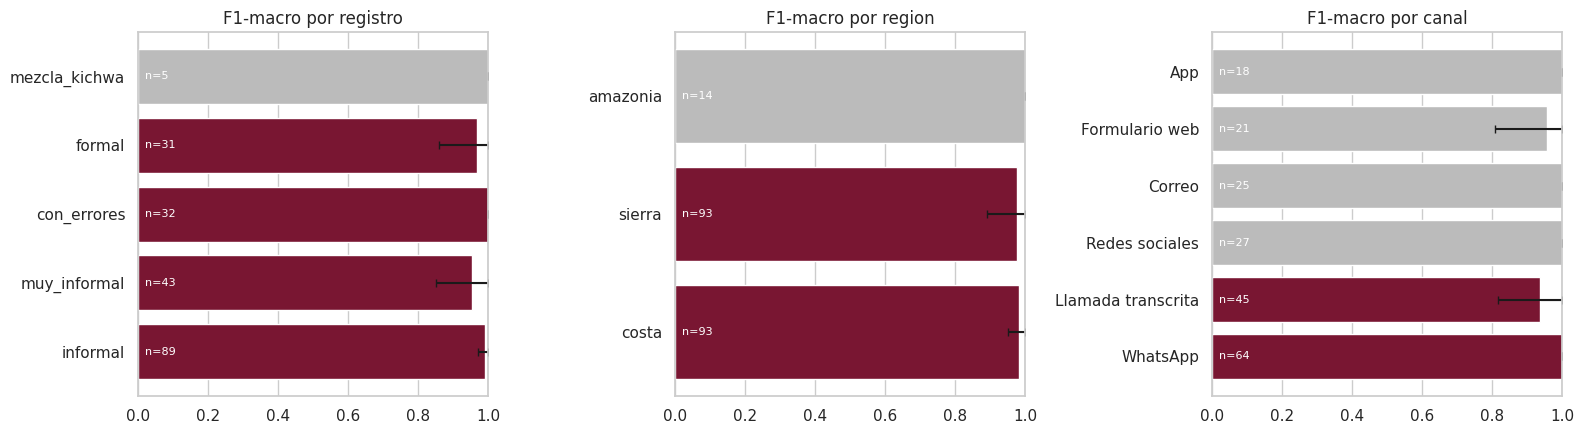

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, col in zip(ax, ["registro", "region", "canal"]):
    sg = pd.DataFrame(equidad[col]["tabla"])
    colores = [GRANATE if c else "#bbbbbb" for c in sg["concluyente"]]
    a.barh(sg["grupo"], sg["f1_macro"], xerr=[sg["f1_macro"] - sg["ic_inf"], sg["ic_sup"] - sg["f1_macro"]], color=colores, capsize=3)
    for y, (n, f) in enumerate(zip(sg["n"], sg["f1_macro"])): a.text(0.02, y, f"n={n}", va="center", color="white", fontsize=8)
    a.set_xlim(0, 1); a.set_title(f"F1-macro por {col}")
guardar_fig("05_equidad_subgrupos")

Gris = subgrupo con menos de 30 casos: se muestra, pero no se usa para concluir.

In [11]:
from fairlearn.metrics import MetricFrame
mf = MetricFrame(metrics={"recall_alta": lambda y, p: recall_clase(y, p, "alta"), "n": lambda y, p: len(y)},
                 y_true=test["prioridad"], y_pred=pred["prioridad"], sensitive_features=t["escritura"])
print("Recall de prioridad alta por forma de escribir (igualdad de oportunidad):")
display(mf.by_group.round(3))
print("Diferencia máxima:", round(float(mf.difference()["recall_alta"]), 3))

Recall de prioridad alta por forma de escribir (igualdad de oportunidad):


,recall_alta,n
escritura,,
estandar,0.920,120.0
no_estandar,0.923,80.0


Diferencia máxima: 0.003


## 6. Abstención y cobertura

Abstención total en la prueba con umbral 0.59: 12.5%


,registro,tasa_abstencion,n
0,con_errores,0.062,32
1,formal,0.226,31
2,informal,0.112,89
3,mezcla_kichwa,0.000,5
4,muy_informal,0.140,43


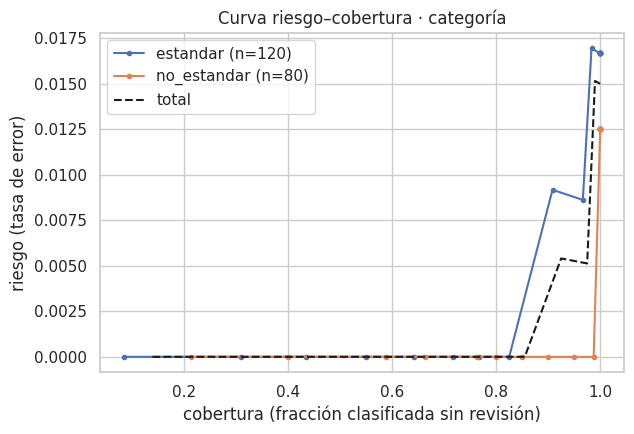

In [12]:
t["conf"] = np.minimum(conf["categoria"], conf["prioridad"])
abst = {col: abstencion_por_subgrupo(t, col, "conf", UMBRAL).to_dict("records") for col in ["escritura", "registro", "region"]}
print(f"Abstención total en la prueba con umbral {UMBRAL:.2f}: {np.mean(t['conf'] < UMBRAL):.1%}")
display(pd.DataFrame(abst["registro"]).round(3))
rc = riesgo_cobertura(test["categoria"], pred["categoria"], t["conf"])
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for g, sub in t.groupby("escritura"):
    r = riesgo_cobertura(sub["categoria"], sub["pred_cat"], sub["conf"])
    ax.plot(r["cobertura"], r["riesgo"], "o-", ms=3, label=f"{g} (n={len(sub)})")
ax.plot(rc["cobertura"], rc["riesgo"], "k--", label="total")
ax.set_xlabel("cobertura (fracción clasificada sin revisión)"); ax.set_ylabel("riesgo (tasa de error)")
ax.set_title("Curva riesgo–cobertura · categoría"); ax.legend()
guardar_fig("05_riesgo_cobertura")

## 7. Pruebas de estrés (escenarios simulados)

El modelo **no se reentrena** salvo en D y F. Cada escenario con azar se repite 10 veces; se reporta la media. Veredicto: **FALLA** si la caída del F1-macro de categoría supera 0,05.

In [13]:
REP = 2 if PRUEBA_RAPIDA else 10
f1_base = res["categoria"]["f1_macro"]
def f1_textos(textos, y=test["categoria"], m=modelo.modelos["categoria"]):
    return metricas(y, m.predict(list(textos)))["f1_macro"]
estres = []
def registrar(esc, nivel, f1, nota=""):
    estres.append({"escenario": esc, "nivel": nivel, "f1_macro": f1, "caida": f1_base - f1,
                   "veredicto": "OK" if f1_base - f1 <= E["caida_max_estres"] else "FALLA", "nota": nota})
# A · erratas
for tasa in [0.1, 0.2, 0.4]:
    registrar("A. Erratas", f"{int(tasa * 100)} % de palabras", np.mean([f1_textos(test["texto"].map(lambda x: con_erratas(x, tasa, s))) for s in range(REP)]))
# B · información faltante
for fr in [0.75, 0.5, 0.25]:
    registrar("B. Mensaje truncado", f"conserva {int(fr * 100)} %", f1_textos(test["texto"].map(lambda x: truncar(x, fr))))
for tasa in [0.1, 0.3, 0.5]:
    registrar("B. Palabras faltantes", f"{int(tasa * 100)} % eliminadas", np.mean([f1_textos(test["texto"].map(lambda x: quitar_palabras(x, tasa, s))) for s in range(REP)]))
# E · términos clave que no llegan
svm_cat = modelo.modelos["categoria"]
coef = np.mean([c.estimator.coef_ for c in svm_cat.named_steps["clf"].calibrated_classifiers_], axis=0)
nombres = svm_cat.named_steps["rasgos"].get_feature_names_out()
for k in [3, 10]:
    clave = {nombres[j].split("__")[1] for fila in coef for j in fila.argsort()[::-1][:k] if nombres[j].startswith("palabra__") and " " not in nombres[j]}
    registrar("E. Palabras clave ausentes", f"top {k} por clase ({len(clave)} palabras)", f1_textos(test["texto"].map(lambda x: quitar_terminos(x, clave))))
pd.DataFrame(estres).round(3)

,escenario,nivel,f1_macro,caida,veredicto,nota
0,A. Erratas,10 % de palabras,0.986,-0.001,OK,
1,A. Erratas,20 % de palabras,0.975,0.010,OK,
2,A. Erratas,40 % de palabras,0.969,0.016,OK,
3,B. Mensaje truncado,conserva 75 %,0.966,0.019,OK,
4,B. Mensaje truncado,conserva 50 %,0.898,0.086,FALLA,
5,B. Mensaje truncado,conserva 25 %,0.681,0.304,FALLA,
6,B. Palabras faltantes,10 % eliminadas,0.958,0.027,OK,
7,B. Palabras faltantes,30 % eliminadas,0.922,0.062,FALLA,
8,B. Palabras faltantes,50 % eliminadas,0.838,0.147,FALLA,
9,E. Palabras clave ausentes,top 3 por clase (10 palabras),0.965,0.020,OK,


In [14]:
# C · desbalance: la exactitud engaña
desbalance = []
for prev in [0.5, 0.8, 0.95]:
    acc, f1s = [], []
    for s in range(REP):
        rng = np.random.default_rng(s)
        mayo = test[test["categoria"] == "SIN_SERVICIO"]; resto = test[test["categoria"] != "SIN_SERVICIO"]
        n_resto = int(round(len(mayo) * (1 - prev) / prev))
        sub = pd.concat([mayo, resto.sample(min(n_resto, len(resto)), random_state=s)])
        m = metricas(sub["categoria"], svm_cat.predict(sub["texto"]))
        acc.append(m["exactitud"]); f1s.append(m["f1_macro"])
    desbalance.append({"prevalencia_sin_servicio": prev, "exactitud": np.mean(acc), "f1_macro": np.mean(f1s)})
pd.DataFrame(desbalance).round(3)

,prevalencia_sin_servicio,exactitud,f1_macro
0,0.50,0.988,0.981
1,0.80,0.995,0.980
2,0.95,1.000,1.000


En C no hay veredicto: muestra que, cuando una categoría domina, la exactitud puede verse alta aunque el modelo falle en las demás. Por eso la métrica principal es F1-macro.

In [15]:
# D · cambio de distribución: entrenar sin escritura no estándar y probar por forma de escribir
p_cat = modelo.metadatos["params"]["categoria"]
estandar = ~dev["registro"].isin(["muy_informal", "con_errores", "mezcla_kichwa"])
m_d = construir_svm(p_cat, SEMILLA).fit(dev.loc[estandar, "texto"], dev.loc[estandar, "categoria"])
ne = t["escritura"] == "no_estandar"
f1_ne_completo = metricas(t.loc[ne, "categoria"], t.loc[ne, "pred_cat"])["f1_macro"]
f1_ne_sin = metricas(t.loc[ne, "categoria"], m_d.predict(t.loc[ne, "texto"]))["f1_macro"]
estres.append({"escenario": "D. Sin escritura no estándar en entrenamiento", "nivel": f"prueba no estándar (n={int(ne.sum())})",
               "f1_macro": f1_ne_sin, "caida": f1_ne_completo - f1_ne_sin,
               "veredicto": "OK" if f1_ne_completo - f1_ne_sin <= E["caida_max_estres"] else "FALLA",
               "nota": "caída frente al modelo entrenado con todos los registros"})
# D · región: entrenar solo con la costa y probar con sierra y amazonía
costa = dev["region"] == "costa"
m_r = construir_svm(p_cat, SEMILLA).fit(dev.loc[costa, "texto"], dev.loc[costa, "categoria"])
otras = t["region"] != "costa"
f1_otras = metricas(t.loc[otras, "categoria"], m_r.predict(t.loc[otras, "texto"]))["f1_macro"]
f1_otras_completo = metricas(t.loc[otras, "categoria"], t.loc[otras, "pred_cat"])["f1_macro"]
estres.append({"escenario": "D. Entrenado solo con la costa", "nivel": f"prueba sierra y amazonía (n={int(otras.sum())})",
               "f1_macro": f1_otras, "caida": f1_otras_completo - f1_otras,
               "veredicto": "OK" if f1_otras_completo - f1_otras <= E["caida_max_estres"] else "FALLA", "nota": ""})
# F (propio) · etiquetas ruidosas en el entrenamiento
clases_cat = sorted(dev["categoria"].unique())
for tasa in [0.1, 0.2, 0.3]:
    vals = []
    for s in range(max(1, REP // 5)):
        rng = np.random.default_rng(s); y = dev["categoria"].copy()
        idx = rng.choice(len(y), int(tasa * len(y)), replace=False)
        y.iloc[idx] = rng.choice(clases_cat, len(idx))
        vals.append(f1_textos(test["texto"], m=construir_svm(p_cat, SEMILLA).fit(dev["texto"], y)))
    registrar("F. Etiquetas ruidosas (propio)", f"{int(tasa * 100)} % de etiquetas cambiadas", np.mean(vals))
# F (propio) · quejas difíciles
for dif in ["ambigua", "dos_problemas"]:
    s = t["dificultad"] == dif
    registrar("F. Quejas difíciles (propio)", f"{dif} (n={int(s.sum())})", metricas(t.loc[s, "categoria"], t.loc[s, "pred_cat"])["f1_macro"],
              "n < 30: sin conclusión" if s.sum() < 30 else "")
tabla_estres = pd.DataFrame(estres)
display(tabla_estres.round(3))

,escenario,nivel,f1_macro,caida,veredicto,nota
0,A. Erratas,10 % de palabras,0.986,-0.001,OK,
1,A. Erratas,20 % de palabras,0.975,0.010,OK,
2,A. Erratas,40 % de palabras,0.969,0.016,OK,
3,B. Mensaje truncado,conserva 75 %,0.966,0.019,OK,
4,B. Mensaje truncado,conserva 50 %,0.898,0.086,FALLA,
5,B. Mensaje truncado,conserva 25 %,0.681,0.304,FALLA,
6,B. Palabras faltantes,10 % eliminadas,0.958,0.027,OK,
7,B. Palabras faltantes,30 % eliminadas,0.922,0.062,FALLA,
8,B. Palabras faltantes,50 % eliminadas,0.838,0.147,FALLA,
9,E. Palabras clave ausentes,top 3 por clase (10 palabras),0.965,0.020,OK,


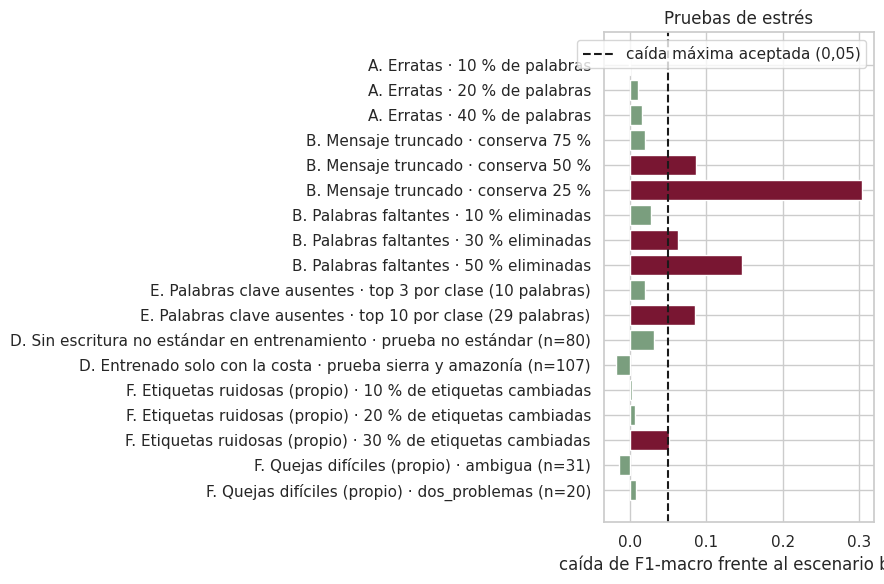

In [16]:
fig, ax = plt.subplots(figsize=(9, 6))
te = tabla_estres.iloc[::-1]
ax.barh(te["escenario"] + " · " + te["nivel"], te["caida"], color=[GRANATE if v == "FALLA" else "#7a9e7e" for v in te["veredicto"]])
ax.axvline(E["caida_max_estres"], ls="--", color="k", label="caída máxima aceptada (0,05)")
ax.set_xlabel("caída de F1-macro frente al escenario base"); ax.set_title("Pruebas de estrés"); ax.legend()
guardar_fig("05_pruebas_estres")

## 8. Análisis de errores

In [17]:
err = t[t["categoria"] != t["pred_cat"]]
conf_pares = err.groupby(["categoria", "pred_cat"]).size().sort_values(ascending=False).head(5)
print("Confusiones más frecuentes:"); display(conf_pares)
ejemplos_error = []
for (real, predicha), _ in conf_pares.items():
    for txt in err[(err["categoria"] == real) & (err["pred_cat"] == predicha)]["texto"].head(2):
        ejemplos_error.append({"real": real, "predicha": predicha, "texto": txt}); print(f"[{real} → {predicha}] {txt}")

Confusiones más frecuentes:


categoria                  pred_cat       
CANCELACION_TRASLADO_PLAN  FACTURACION        1
INTERMITENCIA              VELOCIDAD_LENTA    1
                           WIFI_EQUIPO        1
dtype: int64

[CANCELACION_TRASLADO_PLAN → FACTURACION] alo buenas mire quiero quitar la television del paquete y dejar solo el internet porque ya ni la veo llego tarde del trabajo cuanto me baja la mensualidad
[INTERMITENCIA → VELOCIDAD_LENTA] Aló, buenas tardes. Diez días con caídas constantes en mi centro de copiado.
[INTERMITENCIA → WIFI_EQUIPO] Diez días con cortes constantes; el router además se recalienta.


## 9. Desempeño en el tiempo (latencia)

In [18]:
textos = test["texto"].tolist() * 5
tiempos = []
for x in textos[: (100 if PRUEBA_RAPIDA else 1000)]:
    t0 = time.perf_counter(); modelo.predecir(x); tiempos.append((time.perf_counter() - t0) * 1000)
lat = {"p50_ms": float(np.percentile(tiempos, 50)), "p95_ms": float(np.percentile(tiempos, 95)), "n": len(tiempos)}
print(f"Latencia por queja (CPU): mediana {lat['p50_ms']:.1f} ms · p95 {lat['p95_ms']:.1f} ms (meta ≤ 300 ms)")

Latencia por queja (CPU): mediana 51.5 ms · p95 63.4 ms (meta ≤ 300 ms)


In [19]:
guardar_json({"umbral_abstencion": UMBRAL, "metricas": res, "comparacion_xlmr": comparacion,
              "prioridad": {"recall_alta": rec_alta, "costo_esperado": costo, "costo_siempre_media": costo_dummy, "costos": {f"{a}->{b}": v for (a, b), v in COSTOS.items()}},
              "equidad": equidad, "recall_alta_por_escritura": mf.by_group.to_dict(), "abstencion": abst,
              "abstencion_total": float(np.mean(t["conf"] < UMBRAL)), "riesgo_cobertura": rc.to_dict("records"),
              "estres": tabla_estres.to_dict("records"), "desbalance": desbalance, "errores": ejemplos_error, "latencia": lat},
             f"{MET}/05_evaluacion.json")

PosixPath('/content/drive/MyDrive/triajeia-isp/results/metrics/05_evaluacion.json')

In [20]:
# Guarda el registro del entorno. En Colab, los resultados ya quedaron en Google Drive
# (MyDrive/triajeia-isp/results y models). Descargue además este notebook con sus salidas:
# Archivo → Descargar → .ipynb, y colóquelo en notebooks/ del repositorio.
guardar_json(entorno(), f"{MET}/entorno_{NB}.json")
print("Listo:", NB)

Listo: 05
